# Лабораторна робота №8
## Порівняння та оптимізація моделей машинного навчання

**Мета:** отримати досвід порівняння та оптимізації моделей машинного навчання; застосувати Pipeline, cross-validation, Grid Search і Random Search, дослідити вплив налаштувань моделей на точність, час виконання та обчислювальну складність.

## 1. Набір даних

Використано набір **Telco Customer Churn** з попередніх робіт. Задача - класифікація: цільова змінна `Churn` показує, чи пішов клієнт (1) чи залишився (0). Вхідні ознаки - 19 характеристик клієнта (послуги, контракт, оплата, платежі).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time

pd.set_option("display.max_colwidth", None)

In [2]:
df = pd.read_csv("data/WA_Fn-UseC_-Telco-Customer-Churn.csv")

df = df.drop(columns=["customerID"])
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df = df.drop_duplicates()
df["Churn"] = df["Churn"].map({"Yes": 1, "No": 0})

y = df["Churn"]
X = df.drop(columns=["Churn"])

print("Кількість записів:", len(df))
print("Розмір X:", X.shape)

Кількість записів: 7021
Розмір X: (7021, 19)


## 2. Попередній аналіз даних

In [3]:
numeric_columns = ["tenure", "MonthlyCharges", "TotalCharges"]
categorical_columns = list(X.select_dtypes(include="object").columns)

print("Типи ознак:", X.dtypes.astype(str).value_counts().to_dict())
print("Числові ознаки:", numeric_columns)
print("Категоріальних ознак:", len(categorical_columns))
print("Пропусків:", X.isnull().sum().to_dict()["TotalCharges"], "(тільки TotalCharges)")
print("Розподіл класів:", y.value_counts(normalize=True).round(3).to_dict())

Типи ознак: {'object': 15, 'int64': 2, 'float64': 2}
Числові ознаки: ['tenure', 'MonthlyCharges', 'TotalCharges']
Категоріальних ознак: 15
Пропусків: 11 (тільки TotalCharges)
Розподіл класів: {0: 0.736, 1: 0.264}


In [4]:
X[numeric_columns].describe().loc[["mean", "std", "min", "max"]].round(2)

,tenure,MonthlyCharges,TotalCharges
mean,32.47,64.85,2290.35
std,24.53,30.07,2266.82
min,0.00,18.25,18.80
max,72.00,118.75,8684.80


Після очищення (як у ЛР1) маємо 7021 клієнта і 19 ознак: 15 текстових, 3 неперервні числові (`tenure`, `MonthlyCharges`, `TotalCharges`) і `SeniorCitizen` (0/1).

- **Пропуски:** тільки 11 у `TotalCharges`, їх заповнюватиме імпутер усередині Pipeline.
- **Розподіл цілі:** незбалансований, 73.6% клієнтів залишились і 26.4% пішли. Тому головна метрика - F1-score для класу 1, а поділ і крос-валідація стратифіковані.
- **Попередня обробка потрібна:** числові ознаки мають дуже різні діапазони (`tenure` до 72, `TotalCharges` до 8685), тому для Logistic Regression і k-NN потрібне масштабування; текстові ознаки треба закодувати One-Hot.

## 3. Поділ на навчальну та тестову вибірки

In [5]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Train:", X_train.shape, " частка класу 1:", round(y_train.mean(), 3))
print("Test:", X_test.shape, " частка класу 1:", round(y_test.mean(), 3))

Train: (5616, 19)  частка класу 1: 0.264
Test: (1405, 19)  частка класу 1: 0.265


Дані поділено 80/20 зі `stratify`. Окрема валідаційна вибірка не потрібна: її роль виконує крос-валідація на навчальній вибірці. Тестова вибірка (1405 клієнтів) не використовується ні для навчання, ні для вибору гіперпараметрів, тільки для остаточної оцінки в пункті 14.

## 4. Вибір моделей

Обрано чотири моделі, які працюють за різними принципами:
- **Logistic Regression** - лінійна модель, у ЛР3 вона була найкращою на цих даних;
- **k-NN** - класифікація за найближчими сусідами, чутлива до масштабу і до параметра k;
- **Decision Tree** - одне дерево рішень, схильне до перенавчання;
- **Random Forest** - ансамбль дерев.

Усі моделі порівнюються на однакових даних, з однаковою обробкою і однаковою процедурою оцінювання.

## 5. Побудова Pipeline

In [6]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), numeric_columns),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical_columns),
    ("senior", "passthrough", ["SeniorCitizen"])
])

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "k-NN": KNeighborsClassifier(),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42, n_jobs=-1)
}

pipelines = {}
for name, model in models.items():
    pipelines[name] = Pipeline([
        ("prep", clone(preprocessor)),
        ("model", model)
    ])

print("Створені Pipeline:", list(pipelines.keys()))
pipelines["Random Forest"]

Створені Pipeline: ['Logistic Regression', 'k-NN', 'Decision Tree', 'Random Forest']


Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['tenure', 'MonthlyCharges',
                                                   'TotalCharges']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['gender', 'Partner',
                                                   'Dependents', 'PhoneService',
                                                   'MultipleLines',
                                                   'InternetService',
                                                   'OnlineSecurity',
                                                   'OnlineBackup',
                                                   'DeviceProtection',
                                                   'TechSupport', 'StreamingTV',
                                                   'StreamingMovies',
                                                   'Contract',
                                                   'PaperlessBilling',
                                                   'PaymentMethod']),
                                                 ('senior', 'passthrough',
                                                  ['SeniorCitizen'])])),
                ('model', RandomForestClassifier(n_jobs=-1, random_state=42))])

Кожен Pipeline складається з двох кроків: `prep` (обробка даних) і `model` (сама модель). Препроцесор - це `ColumnTransformer`:
- **числові ознаки:** заповнення медіаною і стандартизація;
- **категоріальні:** заповнення найчастішим значенням і One-Hot;
- **`SeniorCitizen`:** без змін.

Для дерев масштабування не потрібне, але воно їм і не шкодить, тому для однаковості препроцесор спільний. `clone` дає кожному Pipeline окрему ненавчену копію препроцесора. Головна перевага Pipeline саме для крос-валідації: на кожному fold імпутер, скейлер і енкодер навчаються тільки на навчальній частині цього fold, тому витоку даних немає.

## 6-7. Навчання базових моделей з крос-валідацією

In [7]:
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
metrics = ["accuracy", "precision", "recall", "f1"]

cv_rows = []
cv_f1_folds = {}

for name, pipeline in pipelines.items():
    scores = cross_validate(pipeline, X_train, y_train, cv=cv, scoring=metrics)
    row = {"Модель": name}
    for metric in metrics:
        row[metric + " mean"] = scores["test_" + metric].mean()
        row[metric + " std"] = scores["test_" + metric].std()
    row["Час fit (fold), с"] = scores["fit_time"].mean()
    cv_rows.append(row)
    cv_f1_folds[name] = scores["test_f1"]

cv_table = pd.DataFrame(cv_rows)
cv_table.round(3)

,Модель,accuracy mean,accuracy std,precision mean,precision std,recall mean,recall std,f1 mean,f1 std,"Час fit (fold), с"
0,Logistic Regression,0.803,0.013,0.653,0.029,0.547,0.028,0.596,0.027,0.039
1,k-NN,0.770,0.008,0.568,0.018,0.547,0.009,0.557,0.012,0.030
2,Decision Tree,0.731,0.007,0.491,0.014,0.502,0.028,0.496,0.019,0.051
3,Random Forest,0.791,0.013,0.636,0.033,0.488,0.024,0.552,0.028,0.207


In [8]:
pd.DataFrame(cv_f1_folds, index=["Fold " + str(i) for i in range(1, 6)]).round(3)

,Logistic Regression,k-NN,Decision Tree,Random Forest
Fold 1,0.619,0.550,0.517,0.565
Fold 2,0.607,0.547,0.463,0.552
Fold 3,0.565,0.547,0.510,0.524
Fold 4,0.626,0.572,0.490,0.597
Fold 5,0.561,0.570,0.501,0.523


## 8. Порівняння середніх значень і стабільності

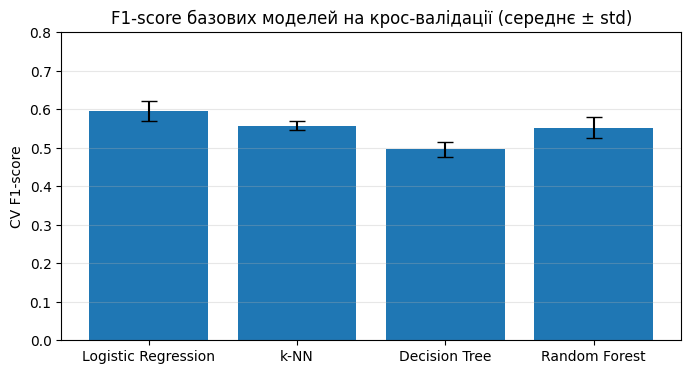

In [9]:
plt.figure(figsize=(8, 4))
plt.bar(cv_table["Модель"], cv_table["f1 mean"], yerr=cv_table["f1 std"], capsize=6)
plt.title("F1-score базових моделей на крос-валідації (середнє ± std)")
plt.ylabel("CV F1-score")
plt.ylim(0, 0.8)
plt.grid(axis="y", alpha=0.3)
plt.show()

Крос-валідація `StratifiedKFold(5)`: навчальна вибірка ділиться на 5 частин з однаковою часткою класів; модель 5 разів навчається на 4 частинах і перевіряється на п'ятій. У таблиці середнє (mean) і стандартне відхилення (std) кожної метрики за 5 прогонами.

- **Logistic Regression** - найкраща базова модель: F1 **0.596**, accuracy 0.803, precision 0.653.
- **k-NN** (F1 0.557) і **Random Forest** (0.552) майже рівні. Ліс має вищу precision (0.636), але найнижчий recall (0.488).
- **Decision Tree** - найгірша (F1 0.496, accuracy 0.731): без обмежень вона перенавчається, як ми бачили в ЛР4.

**Стабільність.** Найстабільніший k-NN (std F1 0.012): по fold його F1 змінюється лише від 0.547 до 0.572. У Logistic Regression і Random Forest std близько 0.027-0.028 (F1 від 0.56 до 0.63), тобто результат одного випадкового поділу міг би відрізнятися на 6 пунктів. Саме тому порівнювати моделі за одним поділом ненадійно. Найшвидше навчаються k-NN і Logistic Regression (0.03-0.04 с на fold), Random Forest приблизно в 5 разів довше (0.21 с).

## 9. Гіперпараметри для оптимізації

In [10]:
grid_params = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [5, 10, None],
    "model__min_samples_leaf": [1, 5],
    "model__max_features": ["sqrt", "log2"]
}

from scipy.stats import randint

random_params = {
    "model__n_neighbors": randint(3, 51),
    "model__weights": ["uniform", "distance"],
    "model__p": [1, 2]
}

print("Random Forest - Grid Search, комбінацій:", 2 * 3 * 2 * 2)
print("k-NN - Random Search, усього можливих комбінацій:", 48 * 2 * 2)

Random Forest - Grid Search, комбінацій: 24
k-NN - Random Search, усього можливих комбінацій: 192


Для оптимізації обрано дві моделі з базовими параметрами нижче за Logistic Regression, які мають важливі гіперпараметри:

**Random Forest (Grid Search):**
- `n_estimators` (100, 200) - кількість дерев;
- `max_depth` (5, 10, None) - глибина дерев, головний параметр проти перенавчання;
- `min_samples_leaf` (1, 5) - мінімум об'єктів у листку;
- `max_features` (sqrt, log2) - скільки ознак розглядати в кожному вузлі.

Разом 2 × 3 × 2 × 2 = **24 комбінації**, з 5 fold це 120 навчань.

**k-NN (Random Search):**
- `n_neighbors` - випадкове ціле від 3 до 50;
- `weights` - чи всі сусіди голосують однаково (`uniform`), чи ближчі мають більшу вагу (`distance`);
- `p` - тип відстані: 1 - манхеттенська, 2 - евклідова.

Усього 48 × 2 × 2 = **192 комбінації**, з них випадково перевіряється 20.

## 10. Grid Search для Random Forest

In [11]:
from sklearn.model_selection import GridSearchCV

grid_search = GridSearchCV(pipelines["Random Forest"], grid_params, scoring="f1", cv=cv)

start = time.time()
grid_search.fit(X_train, y_train)
grid_time = time.time() - start

print("Простір пошуку:", grid_params)
print("Перевірено конфігурацій:", len(grid_search.cv_results_["params"]))
print("Навчань моделі:", len(grid_search.cv_results_["params"]) * 5)
print("Найкращі параметри:", grid_search.best_params_)
print("Найкращий CV F1:", round(grid_search.best_score_, 4))
print("Час пошуку, с:", round(grid_time, 1))

Простір пошуку: {'model__n_estimators': [100, 200], 'model__max_depth': [5, 10, None], 'model__min_samples_leaf': [1, 5], 'model__max_features': ['sqrt', 'log2']}
Перевірено конфігурацій: 24
Навчань моделі: 120
Найкращі параметри: {'model__max_depth': 10, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 5, 'model__n_estimators': 200}
Найкращий CV F1: 0.5842
Час пошуку, с: 44.6


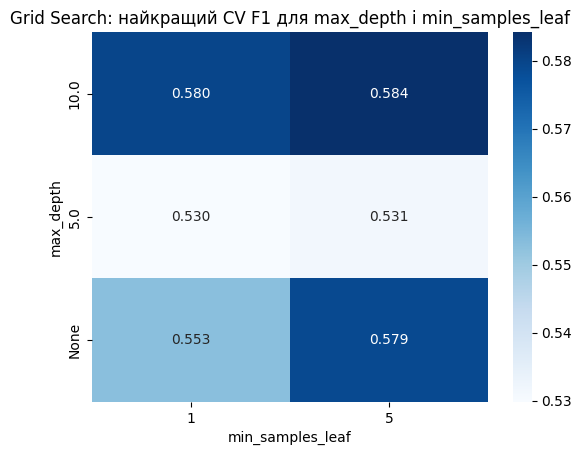

In [12]:
grid_results = pd.DataFrame(grid_search.cv_results_["params"])
grid_results["CV F1"] = grid_search.cv_results_["mean_test_score"]
grid_results["model__max_depth"] = grid_results["model__max_depth"].fillna("None").astype(str)

heatmap_data = grid_results.pivot_table(index="model__max_depth", columns="model__min_samples_leaf", values="CV F1", aggfunc="max")

sns.heatmap(heatmap_data, annot=True, fmt=".3f", cmap="Blues")
plt.title("Grid Search: найкращий CV F1 для max_depth і min_samples_leaf")
plt.xlabel("min_samples_leaf")
plt.ylabel("max_depth")
plt.show()

Grid Search перевірив усі 24 комбінації (120 навчань) за **44.6 с**. Найкраща конфігурація: `max_depth = 10`, `max_features = "sqrt"`, `min_samples_leaf = 5`, `n_estimators = 200`, CV F1 **0.584** (базовий ліс мав 0.552).

Heatmap показує найкращий F1 для кожної пари `max_depth` × `min_samples_leaf`:
- з глибиною 5 дерева занадто прості: F1 лише 0.530;
- без обмеження глибини і з `min_samples_leaf = 1` дерева перенавчаються: 0.553;
- найкраще глибина 10, а `min_samples_leaf = 5` додатково стримує перенавчання.

## 11. Random Search для k-NN

In [13]:
from sklearn.model_selection import RandomizedSearchCV

random_search = RandomizedSearchCV(pipelines["k-NN"], random_params, n_iter=20,
                                   scoring="f1", cv=cv, random_state=42)

start = time.time()
random_search.fit(X_train, y_train)
random_time = time.time() - start

print("Простір пошуку: n_neighbors 3-50, weights [uniform, distance], p [1, 2]")
print("Перевірено конфігурацій:", len(random_search.cv_results_["params"]))
print("Навчань моделі:", len(random_search.cv_results_["params"]) * 5)
print("Найкращі параметри:", random_search.best_params_)
print("Найкращий CV F1:", round(random_search.best_score_, 4))
print("Час пошуку, с:", round(random_time, 1))

Простір пошуку: n_neighbors 3-50, weights [uniform, distance], p [1, 2]
Перевірено конфігурацій: 20
Навчань моделі: 100
Найкращі параметри: {'model__n_neighbors': 41, 'model__p': 2, 'model__weights': 'uniform'}
Найкращий CV F1: 0.6049
Час пошуку, с: 12.0


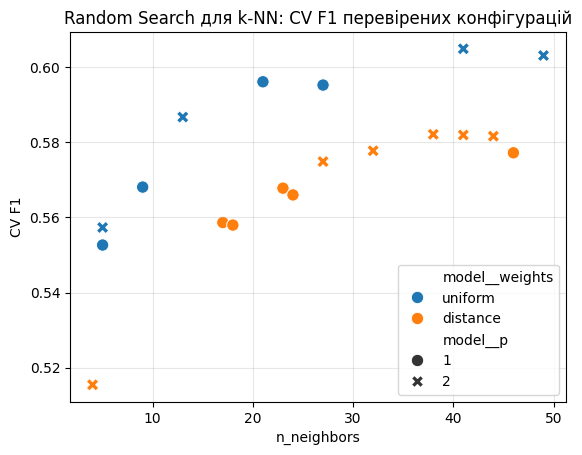

In [14]:
random_results = pd.DataFrame(random_search.cv_results_["params"])
random_results["CV F1"] = random_search.cv_results_["mean_test_score"]

sns.scatterplot(data=random_results, x="model__n_neighbors", y="CV F1", hue="model__weights", style="model__p", s=80)
plt.title("Random Search для k-NN: CV F1 перевірених конфігурацій")
plt.xlabel("n_neighbors")
plt.grid(alpha=0.3)
plt.show()

Random Search перевірив 20 випадкових комбінацій із 192 (100 навчань) за **12.0 с**. Найкраща конфігурація: `n_neighbors = 41`, `p = 2` (евклідова відстань), `weights = "uniform"`, CV F1 **0.605** (базовий k-NN з k = 5 мав 0.557).

На графіку видно, що F1 росте зі збільшенням k: при малих k (3-5) F1 близько 0.52-0.56, бо модель реагує на шум, а при k = 40-50 доходить до 0.60. Варіант `uniform` (сині точки) в основному кращий за `distance` (помаранчеві): з `distance` найближчі сусіди мають дуже велику вагу, і модель знову стає чутливою до шуму.

## 12. Результати пошуку гіперпараметрів

In [15]:
search_table = pd.DataFrame([
    {
        "Метод": "Grid Search",
        "Модель": "Random Forest",
        "Конфігурацій": len(grid_search.cv_results_["params"]),
        "Навчань": len(grid_search.cv_results_["params"]) * 5,
        "Найкращі параметри": str(grid_search.best_params_).replace("model__", ""),
        "Найкращий CV F1": grid_search.best_score_,
        "Час пошуку, с": grid_time
    },
    {
        "Метод": "Random Search",
        "Модель": "k-NN",
        "Конфігурацій": len(random_search.cv_results_["params"]),
        "Навчань": len(random_search.cv_results_["params"]) * 5,
        "Найкращі параметри": str(random_search.best_params_).replace("model__", ""),
        "Найкращий CV F1": random_search.best_score_,
        "Час пошуку, с": random_time
    }
])
search_table.round(4)

,Метод,Модель,Конфігурацій,Навчань,Найкращі параметри,Найкращий CV F1,"Час пошуку, с"
0,Grid Search,Random Forest,24,120,"{'max_depth': 10, 'max_features': 'sqrt', 'min_samples_leaf': 5, 'n_estimators': 200}",0.5842,44.6440
1,Random Search,k-NN,20,100,"{'n_neighbors': 41, 'p': 2, 'weights': 'uniform'}",0.6049,11.9804


## 13. Порівняння Grid Search і Random Search

In [16]:
random_rf = RandomizedSearchCV(pipelines["Random Forest"], grid_params, n_iter=12,
                               scoring="f1", cv=cv, random_state=42)

start = time.time()
random_rf.fit(X_train, y_train)
random_rf_time = time.time() - start

pd.DataFrame([
    {"Метод": "Grid Search (усі комбінації)", "Конфігурацій": 24, "Найкращий CV F1": grid_search.best_score_,
     "Найкращі параметри": str(grid_search.best_params_).replace("model__", ""), "Час, с": grid_time},
    {"Метод": "Random Search (12 випадкових)", "Конфігурацій": 12, "Найкращий CV F1": random_rf.best_score_,
     "Найкращі параметри": str(random_rf.best_params_).replace("model__", ""), "Час, с": random_rf_time}
]).round(4)

,Метод,Конфігурацій,Найкращий CV F1,Найкращі параметри,"Час, с"
0,Grid Search (усі комбінації),24,0.5842,"{'max_depth': 10, 'max_features': 'sqrt', 'min_samples_leaf': 5, 'n_estimators': 200}",44.6440
1,Random Search (12 випадкових),12,0.5842,"{'n_estimators': 200, 'min_samples_leaf': 5, 'max_features': 'sqrt', 'max_depth': 10}",23.9955


У таблиці пункту 12 два пошуки працювали з різними моделями, тому напряму їх порівнювати некоректно. Для чесного порівняння Random Search запущено **на тому самому просторі, що й Grid Search для Random Forest**, але лише з 12 випадковими комбінаціями (половина з 24).

**Результат:** Random Search знайшов **ту саму** найкращу конфігурацію (`max_depth = 10`, `sqrt`, `min_samples_leaf = 5`, 200 дерев, CV F1 0.584), але за **24.0 с** замість 44.6 с, тобто майже вдвічі швидше. Тут йому трохи пощастило, що найкраща комбінація потрапила у вибірку, а гарантії цього немає.

**Висновок:**
- Grid Search гарантовано перевіряє все, але його час росте як добуток кількості значень усіх параметрів;
- Random Search дозволяє самому задати бюджет (`n_iter`) і зазвичай знаходить близький до найкращого результат значно швидше, особливо коли параметрів багато або в них широкі діапазони (як `n_neighbors` від 3 до 50 у k-NN).

## 14. Навчання найкращих конфігурацій і оцінка на тестовій вибірці

In [17]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

final_models = {
    ("Logistic Regression", "Базова"): clone(pipelines["Logistic Regression"]),
    ("k-NN", "Базова"): clone(pipelines["k-NN"]),
    ("k-NN", "Random Search"): clone(random_search.best_estimator_),
    ("Decision Tree", "Базова"): clone(pipelines["Decision Tree"]),
    ("Random Forest", "Базова"): clone(pipelines["Random Forest"]),
    ("Random Forest", "Grid Search"): clone(grid_search.best_estimator_)
}

cv_f1 = {
    ("Logistic Regression", "Базова"): cv_table.loc[0, "f1 mean"],
    ("k-NN", "Базова"): cv_table.loc[1, "f1 mean"],
    ("k-NN", "Random Search"): random_search.best_score_,
    ("Decision Tree", "Базова"): cv_table.loc[2, "f1 mean"],
    ("Random Forest", "Базова"): cv_table.loc[3, "f1 mean"],
    ("Random Forest", "Grid Search"): grid_search.best_score_
}

final_rows = []

for (name, variant), model in final_models.items():
    start = time.time()
    model.fit(X_train, y_train)
    train_time = time.time() - start

    start = time.time()
    pred = model.predict(X_test)
    predict_time = time.time() - start

    final_rows.append({
        "Модель": name,
        "Варіант": variant,
        "CV F1": cv_f1[(name, variant)],
        "Test Accuracy": accuracy_score(y_test, pred),
        "Test Precision": precision_score(y_test, pred),
        "Test Recall": recall_score(y_test, pred),
        "Test F1": f1_score(y_test, pred),
        "Навчання, с": train_time,
        "Прогноз, с": predict_time,
        "Прогноз на 1 об'єкт, мс": predict_time / len(X_test) * 1000
    })

final_results = pd.DataFrame(final_rows)
final_results.drop(columns=["Навчання, с", "Прогноз, с", "Прогноз на 1 об'єкт, мс"]).round(3)

,Модель,Варіант,CV F1,Test Accuracy,Test Precision,Test Recall,Test F1
0,Logistic Regression,Базова,0.596,0.803,0.661,0.524,0.585
1,k-NN,Базова,0.557,0.759,0.552,0.487,0.517
2,k-NN,Random Search,0.605,0.796,0.634,0.548,0.588
3,Decision Tree,Базова,0.496,0.717,0.469,0.503,0.485
4,Random Forest,Базова,0.552,0.779,0.617,0.441,0.514
5,Random Forest,Grid Search,0.584,0.800,0.664,0.495,0.567


Усі моделі (базові та оптимізовані) навчено на всій навчальній вибірці і **один раз** оцінено на тестовій:
- **найкращий результат** у k-NN після Random Search: Test F1 **0.588**, accuracy 0.796;
- майже така сама **Logistic Regression** з базовими параметрами: F1 0.585, accuracy 0.803;
- **Random Forest після Grid Search:** F1 0.567 і найвища precision (0.664), але recall нижчий (0.495);
- **найгірше Decision Tree:** F1 0.485.

Test F1 у всіх моделей трохи нижчий за CV F1 (на 0.01-0.04), що нормально для нових даних. Ці числа не можна прямо порівнювати з ЛР3-ЛР4, бо там був інший поділ (70/15/15) і, відповідно, інша тестова вибірка.

## 15. Порівняння початкових і оптимізованих моделей

In [18]:
improvement = []

for name in ["k-NN", "Random Forest"]:
    base = final_results[(final_results["Модель"] == name) & (final_results["Варіант"] == "Базова")].iloc[0]
    tuned = final_results[(final_results["Модель"] == name) & (final_results["Варіант"] != "Базова")].iloc[0]
    improvement.append({
        "Модель": name,
        "CV F1 базова": base["CV F1"],
        "CV F1 оптимізована": tuned["CV F1"],
        "Test F1 базова": base["Test F1"],
        "Test F1 оптимізована": tuned["Test F1"],
        "Приріст Test F1": tuned["Test F1"] - base["Test F1"]
    })

pd.DataFrame(improvement).round(3)

,Модель,CV F1 базова,CV F1 оптимізована,Test F1 базова,Test F1 оптимізована,Приріст Test F1
0,k-NN,0.557,0.605,0.517,0.588,0.071
1,Random Forest,0.552,0.584,0.514,0.567,0.053


Оптимізація помітно покращила обидві моделі:
- **k-NN:** CV F1 з 0.557 до 0.605, Test F1 з 0.517 до 0.588 (+0.071, тобто +14%);
- **Random Forest:** CV F1 з 0.552 до 0.584, Test F1 з 0.514 до 0.567 (+0.053, тобто +10%).

Приріст на тесті підтверджує результат крос-валідації, отже гіперпараметри справді краще узагальнюють, а не просто підігнані під CV. Обидві оптимізовані моделі наздогнали Logistic Regression, яка вже з базовими параметрами була сильною.

## 16. Час навчання і прогнозування

In [19]:
final_results[["Модель", "Варіант", "Навчання, с", "Прогноз, с", "Прогноз на 1 об'єкт, мс"]].round(4)

,Модель,Варіант,"Навчання, с","Прогноз, с","Прогноз на 1 об'єкт, мс"
0,Logistic Regression,Базова,0.0636,0.0115,0.0082
1,k-NN,Базова,0.0362,0.0359,0.0255
2,k-NN,Random Search,0.0372,0.0427,0.0304
3,Decision Tree,Базова,0.0837,0.0113,0.0081
4,Random Forest,Базова,0.2703,0.0385,0.0274
5,Random Forest,Grid Search,0.4875,0.0619,0.0441


**Час навчання** (на всій навчальній вибірці, 5616 клієнтів):
- k-NN (0.04-0.05 с) і Logistic Regression (0.06 с) найшвидші. k-NN фактично лише запам'ятовує дані;
- Decision Tree 0.09 с;
- Random Forest 0.29 с, а після Grid Search (200 дерев замість 100) 0.52 с.

**Час прогнозу на 1 клієнта:**
- найшвидші Logistic Regression і дерево (близько 0.008 мс);
- k-NN з k = 41 повільніший у 5-6 разів (0.043 мс), бо для кожного нового клієнта шукає найближчих серед усіх навчальних;
- Random Forest після оптимізації 0.045 мс, бо прогноз проходить через 200 дерев.

Абсолютні значення дуже малі і залежать від комп'ютера, важливе співвідношення між моделями.

## 17. Підсумкова таблиця

In [20]:
params = {
    "Базова": "за замовчуванням",
    "Grid Search": str(grid_search.best_params_).replace("model__", ""),
    "Random Search": str(random_search.best_params_).replace("model__", "")
}

summary = final_results[["Модель", "Варіант", "CV F1", "Test F1", "Навчання, с", "Прогноз, с"]].copy()
summary.insert(2, "Гіперпараметри", summary["Варіант"].map(params))
summary.round(3)

,Модель,Варіант,Гіперпараметри,CV F1,Test F1,"Навчання, с","Прогноз, с"
0,Logistic Regression,Базова,за замовчуванням,0.596,0.585,0.064,0.011
1,k-NN,Базова,за замовчуванням,0.557,0.517,0.036,0.036
2,k-NN,Random Search,"{'n_neighbors': 41, 'p': 2, 'weights': 'uniform'}",0.605,0.588,0.037,0.043
3,Decision Tree,Базова,за замовчуванням,0.496,0.485,0.084,0.011
4,Random Forest,Базова,за замовчуванням,0.552,0.514,0.270,0.038
5,Random Forest,Grid Search,"{'max_depth': 10, 'max_features': 'sqrt', 'min_samples_leaf': 5, 'n_estimators': 200}",0.584,0.567,0.488,0.062


## 18. Графічне представлення результатів

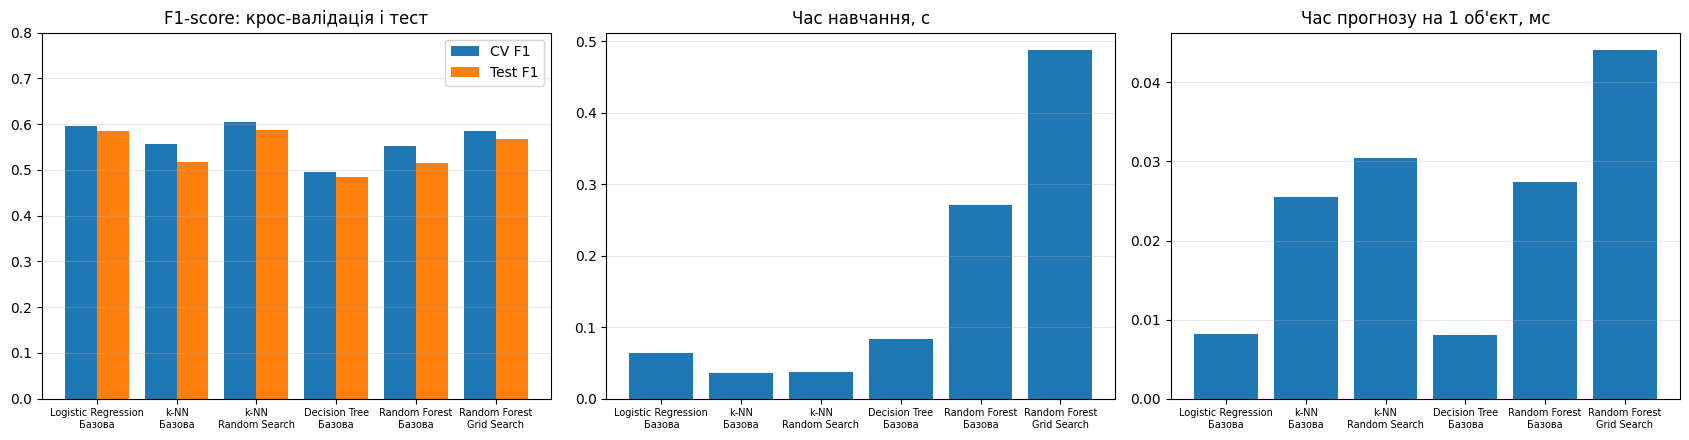

In [21]:
labels = final_results["Модель"] + "\n" + final_results["Варіант"]

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

x = np.arange(len(labels))
axes[0].bar(x - 0.2, final_results["CV F1"], width=0.4, label="CV F1")
axes[0].bar(x + 0.2, final_results["Test F1"], width=0.4, label="Test F1")
axes[0].set_title("F1-score: крос-валідація і тест")
axes[0].set_ylim(0, 0.8)
axes[0].legend()

axes[1].bar(labels, final_results["Навчання, с"])
axes[1].set_title("Час навчання, с")

axes[2].bar(labels, final_results["Прогноз на 1 об'єкт, мс"])
axes[2].set_title("Час прогнозу на 1 об'єкт, мс")

for ax in axes:
    ax.set_xticks(x)
    ax.set_xticklabels(labels, fontsize=7)
    ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

На лівому графіку видно, що для всіх моделей CV F1 (синій) і Test F1 (помаранчевий) близькі, а оптимізовані варіанти k-NN і Random Forest помітно вищі за базові. Середній графік показує, що Random Forest навчається у 5-10 разів довше за інші моделі, а оптимізований ліс з 200 деревами - найдовше. На правому видно, що найповільніший прогноз у оптимізованих k-NN і Random Forest, а Logistic Regression і дерево прогнозують найшвидше.

## 19. Висновки

- **Найбільш ефективна модель.** За якістю на тесті найкращі **k-NN після Random Search** (F1 0.588) і **Logistic Regression** з базовими параметрами (F1 0.585, найвища accuracy 0.803). Різниця між ними 0.003, тобто практично однакова. Але Logistic Regression не потребує налаштування, навчається за 0.06 с і прогнозує в 5-6 разів швидше, тому з урахуванням якості, стабільності і швидкості саме вона найбільш ефективна для цих даних. Decision Tree без обмежень найгірша (F1 0.485) через перенавчання.
- **Вплив оптимізації.** Підбір гіперпараметрів суттєво покращив обидві оптимізовані моделі: k-NN на 0.071 F1 на тесті (найкраще k = 41 замість 5), Random Forest на 0.053 (обмеження глибини до 10 і `min_samples_leaf = 5` прибрали перенавчання). Приріст на тесті підтверджує, що це не випадковість крос-валідації.
- **Крос-валідація.** Стандартне відхилення F1 між fold доходить до 0.028, тобто результат одного поділу міг би відрізнятися на кілька пунктів. Тому порівнювати моделі за середнім 5-fold значно надійніше.
- **Grid Search проти Random Search.** Grid Search перевірив усі 24 комбінації лісу за 44.6 с. Random Search на тому самому просторі з 12 спробами знайшов ту саму найкращу конфігурацію (CV F1 0.584) за 24 с, тобто майже вдвічі швидше. Для k-NN з 192 можливими комбінаціями Random Search за 20 спроб і 12 с знайшов модель, яка дала найкращий результат на тесті. Отже, найкращий компроміс між якістю і обчислювальними витратами дав **Random Search**. Grid Search доцільний, коли простір пошуку невеликий і потрібна гарантія перевірки всіх варіантів.